In [ ]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import torch

import neurogym as ngym
from neurogym.wrappers import ScheduleEnvs, Monitor
from neurogym.utils import plot_env, RandomSchedule, SequentialSchedule
from neurogym.envs import get_collection
from torch.nn import functional as F

from IPython.display import clear_output
from net.common import savefig
warnings.filterwarnings("ignore")
clear_output()

In [ ]:
# Environment parameters
# This setting is low to speed up testing, we recommend setting it to at least 1000
EVAL_TRIALS = 100
dt = 100
dim_ring = 2  # Number of choices in the ring representation
kwargs = {
    "dt": dt,
    "dim_ring": dim_ring,
}
rewards = {
    "abort": -0.1,
    "correct": +1.0,
    "fail": 0.0
}
sigma = 1.0 # Standard deviation of the Gaussian noise in the ring representation
device = 'cuda' if torch.cuda.is_available() else 'cpu'
ob_size = 5
act_size = 3
print(f"ob_size: {ob_size}, act_size: {act_size}"   )

ob_size: 5, act_size: 3


In [ ]:
from net.colei import ColEI
from net.dann import DANN
from net.simple import SimpleNet
from net.eisep import EISepNet
from net.dbp import DBPN
import copy
def train(env, net, env_vec, epoch, batch_size, seq_len, lr):

    net.train()

    class_weights = torch.tensor([0.05] + [1.0]*(act_size - 1)).to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)
    dataset = ngym.Dataset(env, batch_size=batch_size, seq_len=seq_len)

    running_loss = 0.0
    running_entropy = 0.0
    running_decoding_loss = 0.0

    loss_log = np.zeros((epoch, 3))
    gradient_log = np.zeros((epoch, 7))
    grad_log = np.zeros((epoch, net.hidden_size ** 2))  # 新增
    for i in range(epoch):
        # net.set_temperature(get_temperature(i))
        # if i % 10 == 9:
            # print('Epoch:', i+1, 'Temperature:', net.temperature)
        inputs, labels = dataset()

        inputs = np.concatenate([inputs, env_vec.reshape(1,1,-1).repeat(inputs.shape[0], 0).repeat(inputs.shape[1],1)], axis=-1)
        inputs = torch.from_numpy(inputs).type(torch.float).to(device)
        labels = torch.from_numpy(labels.flatten()).type(torch.long).to(device)

        # zero the parameter gradients

        # forward + backward + optimize
        outputs, eimask_logit, hidden = net(inputs)

        decoding_loss = criterion(outputs.reshape(-1, act_size), labels)


        loss = decoding_loss

        if net.entropy_loss:
            # eimask_prob = F.softmax(eimask_logit, dim=-1)
            # eimask_entropy = -torch.sum(eimask_prob * torch.log(eimask_prob + 1e-10), dim=-1)
            # entropy_loss = torch.mean(eimask_entropy)  # Add entropy regularization
            # running_entropy += entropy_loss.item()
            entropy_loss = net.get_ei_entropy_loss()
            loss_log[i, 2] = entropy_loss.item()
        else:
            entropy_loss = 0.0

        loss += entropy_loss * 1.0
        ###TODO: no entropy
        loss.backward()

        # 新增：收集实际权重矩阵的梯度
        if isinstance(net, EISepNet):
            # 取hook捕获的actual梯度
            if hasattr(net.lstm, 'actual_grad_container'):
                grad = net.lstm.actual_grad_container[0].flatten()
                grad_log[i] = (grad / (grad.norm() + 1e-8)).cpu().numpy()
        elif isinstance(net, SimpleNet):
            # Simple RNN直接用Wrec_free.grad
            if net.lstm.Wrec_free.grad is not None:
                grad = net.lstm.Wrec_free.grad.detach().clone().flatten()
                grad_log[i] = (grad / (grad.norm() + 1e-8)).cpu().numpy()


        if isinstance(net, DANN):
            gradient_log[i, 0] = net.danncell.Wex.grad.norm(2).item()
            net.update(lr=lr, max_grad_norm=None)
            net.zero_grad()
        elif isinstance(net, ColEI):
            gradient_log[i, 0] = net.colcell.W_pos.grad.norm(2).item()
            net.update(lr=lr, max_grad_norm=10)
            net.zero_grad()
        elif isinstance(net, DBPN):
            gradient_log[i, 0] = net.rnn.weight_hh_l0.grad.norm(2).item()
            net.update(optimizer)
            optimizer.zero_grad()
        else:
            gradient_log[i, 0] = net.lstm.Wrec_free.grad.norm(2).item()

            if net.entropy_loss:
                gradient_log[i, 6] = net.lstm.eimask_logit.grad.norm(2).item()
            optimizer.step()
            optimizer.zero_grad()
        # gradient_log[i, 0] = net.lstm.input_layer.weight.grad.norm(2).item()
        # gradient_log[i, 1] = net.lstm.input_layer.bias.grad.norm(2).item()
        # gradient_log[i, 2] = net.lstm.Wrec_free.grad.norm(2).item()
        # gradient_log[i, 3] = net.lstm.bias.grad.norm(2).item()
        # gradient_log[i, 4] = net.lstm.output_layer.weight.grad.norm(2).item()
        # gradient_log[i, 5] = net.lstm.output_layer.bias.grad.norm(2).item()
        # if net.entropy_loss:
        #     print(net.lstm.eimask_logit.requires_grad)

        # optimizer.step()
        loss_log[i, 0] = loss.item()
        loss_log[i, 1] = decoding_loss.item()

        # print statistics
        running_loss += loss.item()
        running_decoding_loss += decoding_loss.item()
        if (i+1) % 100 == 0:
            print('{:d} loss: {:0.5f}'.format(i+1, running_loss / 100))
            print('Entropy loss: {:0.5f}, Decoding loss: {:0.5f}'.format(
                running_entropy / 100, running_decoding_loss / 100))
            running_loss = 0.0
            running_entropy = 0.0
            running_decoding_loss = 0.0

    print('Finished Training')
    # 对epoch取平均，得到该任务的平均梯度方向
    mean_grad = grad_log.mean(0)
    mean_grad = mean_grad / (np.linalg.norm(mean_grad) + 1e-8)
    return net, loss_log, gradient_log, mean_grad

def test(env, net, env_vec):
    perf = 0
    num_trial = 200
    net.eval()
    for i in range(num_trial):
        env.seed(i)
        env.new_trial()
        ob, gt = env.ob, env.gt
        ob = ob[:, np.newaxis, :]  # Add batch axis
        ob = np.concatenate([ob, env_vec.reshape(1,1,-1).repeat(ob.shape[0], 0).repeat(ob.shape[1],1)], axis=-1)
        inputs = torch.from_numpy(ob).type(torch.float).to(device)
        action_pred = net(inputs)[0]
        action_pred = action_pred.cpu().detach().numpy()
        action_pred = np.argmax(action_pred, axis=-1)
        perf += gt[-1] == action_pred[-1, 0]
    perf /= num_trial

    return perf
def collect_hidden_states(env, net, env_vec, num_trial=100):
    """
    收集网络在某个任务上的隐层激活。
    返回 shape: (total_timesteps, hidden_size)
    """
    net.eval()
    all_hidden = []
    for i in range(num_trial):
        env.seed(i)
        env.new_trial()
        ob, gt = env.ob, env.gt
        ob = ob[:, np.newaxis, :]  # (T, 1, ob_size)
        ob = np.concatenate(
            [ob, env_vec.reshape(1, 1, -1).repeat(ob.shape[0], 0).repeat(ob.shape[1], 1)],
            axis=-1
        )
        inputs = torch.from_numpy(ob).type(torch.float).to(device)
        with torch.no_grad():
            _, _, hidden = net(inputs)  # hidden: [(T, 1, hidden_size),...]
        all_hidden.append(hidden[0].squeeze(1).cpu().numpy())  # (T, hidden_size)
    return np.concatenate(all_hidden, axis=0)  # (total_T, hidden_size)


def continual_learning(envs, net, epoch, batch_size, seq_len, lr, repeat_times):
    """
    Continual learning on a sequence of environments.
    新增: hidden_state_logs，记录每次训练完后在所有任务上的隐层激活
    """
    test_perfs = np.zeros((repeat_times, len(envs), len(envs)))
    env_vecs = np.eye(len(envs))
    loss_logs = np.zeros((repeat_times, len(envs), epoch, 3))
    gradient_logs = np.zeros((repeat_times, len(envs), epoch, 7))
    net_state_dicts = [[None] * len(envs) for _ in range(repeat_times)]
    delta_W_logs = np.zeros((repeat_times, len(envs), net.hidden_size, net.hidden_size))
    grad_direction_logs = np.zeros((repeat_times, len(envs), net.hidden_size ** 2))  # 新增
    # 新增: hidden_state_logs[k][i][j] = 训练完第i个任务后，在第j个任务上收集的激活
    # 用 object array 存，因为 total_T 可能不同
    # hidden_state_logs = np.empty((len(envs)), dtype=object)

    for k in range(repeat_times):
        for i, env in enumerate(envs):
            W_before_train = net.get_actual_weight().detach().clone()
            net, loss_log, gradient_log, mean_grad = train(env, net, env_vecs[i], epoch, batch_size, seq_len, lr)
            loss_logs[k, i] = loss_log
            gradient_logs[k, i] = gradient_log
            grad_direction_logs[k, i] = mean_grad  # 新增
            net_state_dicts[k][i] = copy.deepcopy(net.state_dict())
            W_after_train = net.get_actual_weight().detach().clone()
            delta_W_logs[k, i] = (W_after_train - W_before_train).detach().cpu().numpy()
            assert W_after_train is not W_before_train


            for j, env_test in enumerate(envs):
                perf = test(env_test, net, env_vecs[j])
                test_perfs[k,i,j] = perf
    # # 训练完成，在所有任务上收集隐层激活
    # for j, env_test in enumerate(envs):
    #     hidden_state_logs[j] = collect_hidden_states(
    #         env_test, net, env_vecs[j], num_trial=collect_trials
    #     )

    return test_perfs, net_state_dicts, loss_logs, gradient_logs, delta_W_logs, grad_direction_logs

def plot_sequential_performance(test_perf_EI, test_perf_simple, seed, env_names):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    for i in range(len(env_names)):
        ax[0].plot(test_perf_EI[:,i], label=f'{env_names[i]} acc')
        ax[1].plot(test_perf_simple[:,i], label=f'{env_names[i]} acc')
    ax[0].set_title('EI-RNN')
    ax[1].set_title('Simple RNN')
    for i in range(2):
        ax[i].set_xticks(range(len(env_names)))
        ax[i].set_xticklabels(env_names)
        # ax[i].set_xmargin(0)
        ax[i].set_xlabel('Training environment')
        ax[i].set_ylabel('Test performance')
        ax[i].legend()
    plt.tight_layout()
    plt.savefig(f'./output/sequential_performance_seed{seed}.png')

def plot_log(log, dir, items):
    fig, ax = plt.subplots(1, 1, figsize=(6, 3))
    for i in range(log.shape[1]):
        ax.plot(log[:, i], label=items[i])
    ax.set_xlabel('Epoch')
    ax.legend()
    plt.tight_layout()
    plt.savefig(dir)
    return


In [ ]:
task_ids = ["go", "dlygo", "anti", "dlyanti"]
# task_ids = ["go", "anti", "dlygo", "dlyanti"]
task = [f"yang19.{task}-v0" for task in task_ids]
envs = [ngym.make(t, **kwargs) for t in task]

In [ ]:
from net.common import init_model
import pickle as pkl
def multiple_train(model_name, lr):
    n_seed = 5
    hidden_size = 64
    epoch = 200
    repeat_times = 10
    batch_size = 32
    seq_len = 100

    test_perf_all = np.zeros((n_seed, repeat_times, len(envs), len(envs)))
    net_state_dicts = [None] * n_seed
    loss_log_all = np.zeros((n_seed, repeat_times, len(envs), epoch, 3))
    gradient_log_all = np.zeros((n_seed, repeat_times, len(envs), epoch, 7))
    delta_W_log_all = np.zeros((n_seed, repeat_times, len(envs), hidden_size, hidden_size))
    grad_direction_log_all = np.zeros((n_seed, repeat_times, len(envs), hidden_size ** 2))  # 新增

    # 新增: object array 存放隐层激活
    for i in range(n_seed):
        print('Seed:', i)
        np.random.seed(i)
        torch.manual_seed(i)
        net = init_model(
            ob_size=ob_size + len(envs),
            hidden_size=hidden_size,
            act_size=act_size,
            model_name=model_name
        ).to(device)
        (test_perf, net_state_dict, loss_log, gradient_log,
         delta_W_log, grad_direction_log) = continual_learning(
            envs, net, epoch, batch_size, seq_len, lr, repeat_times
        )
        test_perf_all[i] = test_perf
        net_state_dicts[i] = net_state_dict
        loss_log_all[i] = loss_log
        gradient_log_all[i] = gradient_log
        delta_W_log_all[i] = delta_W_log
        grad_direction_log_all[i] = grad_direction_log

    info = {
        "test_perf_all": test_perf_all,
        "net_state_dicts": net_state_dicts,
        "loss_log_all": loss_log_all,
        "delta_W_log_all": delta_W_log_all,
        "grad_direction_log_all": grad_direction_log_all
    }
    return info
# ```

# **数据结构说明：**

# `hidden_state_log_all` 的索引含义是：
# ```
# hidden_state_log_all[seed, repeat, after_task_i, on_task_j]
# → shape: (total_timesteps, hidden_size)

In [ ]:
import pickle
# model_names = ['eisep', 'simple', 'dann_sgd', 'dann_adam', 'colei_sgd', 'colei_adam', 'dbpn', 'absolute_eisep', 'fixed_eisep', 'entryei', 'eisep_init_ColEI', 'eisep_init_DBPN']
model_names = ['eisep', 'simple', 'cstr_simple', 'absolute_eisep', 'fixed_eisep', 'entryei', 'eisep_init_ColEI', 'eisep_init_DBPN']
# model_names = ['eisep', 'simple', 'ccstr_simple']
# legend_names = ['EISep', 'Simple', 'EntryEI', 'Fixed-EISep', 'Fixed-EntryEI',  'DANN-SGD', 'DANN-Adam', 'ColEI-SGD', 'ColEI-Adam']
# legend_names = ['EISep', 'Simple', 'DANN-SGD', 'DANN-Adam', 'ColEI-SGD', 'ColEI-Adam', 'DBPN', 'Abs-EISep', 'Fixed-EISep', 'EntryEI', 'EISep(N1)', 'EISep(N2)']
legend_names = ['EISep', 'Simple', 'Cstr-Simple', 'Abs-EISep', 'Fixed-EISep', 'EntryEI', 'EISep(N1)', 'EISep(N2)']
# legend_names = ['EISep', 'Simple', 'Cstr-Simple']
lrs = np.array([0.5, 1e-1, 5e-2, 1e-2, 5e-3, 1e-3, 5e-4, 1e-4])
n_seed = 5
epochs = 3000
hidden_size = 64
len_multilr_envs = 20
n_lr = len(lrs)
test_acc = np.zeros((len(model_names), n_lr, n_seed, len_multilr_envs))
net_state_dicts = []
# colors = ['C1', 'C0', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9']
# colors = ['C1', 'C0', 'C7', 'C8', 'C9', '#E69F00', '#56B4E9']
colors = ['C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', '#E69F00', '#56B4E9']

for i, model_name in enumerate(model_names):
    print(i)
    path = f'./result/multitask/multilr_{model_name}_performance.pkl'
    with open(path, 'rb') as f:
        info = pickle.load(f)
    test_acc[i] = info['performance']
# print(env_names)
test_acc_flatten = test_acc.reshape(len(model_names), len(lrs), -1)
mean_acc = np.mean(test_acc_flatten, axis=-1)
best_lr_idx = np.argmax(mean_acc, axis=-1)
best_lrs = lrs[best_lr_idx]
print(f"Best lrs: {best_lrs}")
best_lr_dict = {model_name: float(best_lr) for model_name, best_lr in zip(model_names, best_lrs)}
print(best_lr_dict)

0
1
2
3
4
5
6
7
Best lrs: [0.01  0.005 0.005 0.01  0.01  0.01  0.01  0.01 ]
{'eisep': 0.01, 'simple': 0.005, 'cstr_simple': 0.005, 'absolute_eisep': 0.01, 'fixed_eisep': 0.01, 'entryei': 0.01, 'eisep_init_ColEI': 0.01, 'eisep_init_DBPN': 0.01}


In [ ]:
import os
# model_names = ['eisep_init_ColEI', 'eisep_init_DBPN']
# model_names = ['dann_sgd', 'dann_adam', 'colei_sgd', 'colei_adam', 'dbpn']
model_names = ['eisep', 'simple']
# model_names = ['dbpn', 'colei_sgd', 'colei_adam', 'dann_sgd', 'dann_adam']
# model_names = ['dann_sgd', 'dann_adam', 'colei_sgd', 'colei_adam', 'dbpn', 'absolute_eisep', 'fixed_eisep', 'entryei', 'eisep_init_ColEI', 'eisep_init_DBPN']

lrs = [best_lr_dict[model_name] for model_name in model_names]
# lrs = [0.01]
print(lrs)
# lrs = [5e-3]
# model_names = ['eisep']
for i, model_name in enumerate(model_names):
    print(model_name)
    info = multiple_train(model_name, lrs[i])
    # path = f'./result/continual_learning_gradient_alignment_reorder/lr{lrs[i]}_{model_name}_info.pkl'
    path = f'./result/continual_learning_gradient_alignment/lr{lrs[i]}_{model_name}_info.pkl'
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, 'wb') as f:
        pkl.dump(info, f)
raise ValueError('stop here')

[0.01]
eisep_noentropy
Seed: 0
Using UnFixed EISep RNN
100 loss: 0.78466
Entropy loss: 0.00000, Decoding loss: 0.78466
200 loss: 0.63191
Entropy loss: 0.00000, Decoding loss: 0.63191
Finished Training
100 loss: 0.61478
Entropy loss: 0.00000, Decoding loss: 0.61478
200 loss: 0.60838
Entropy loss: 0.00000, Decoding loss: 0.60838
Finished Training
100 loss: 0.38271
Entropy loss: 0.00000, Decoding loss: 0.38271
200 loss: 0.15287
Entropy loss: 0.00000, Decoding loss: 0.15287
Finished Training
100 loss: 0.15727
Entropy loss: 0.00000, Decoding loss: 0.15727
200 loss: 0.09144
Entropy loss: 0.00000, Decoding loss: 0.09144
Finished Training
100 loss: 1.17630
Entropy loss: 0.00000, Decoding loss: 1.17630
200 loss: 0.09149
Entropy loss: 0.00000, Decoding loss: 0.09149
Finished Training
100 loss: 0.04958
Entropy loss: 0.00000, Decoding loss: 0.04958
200 loss: 0.01058
Entropy loss: 0.00000, Decoding loss: 0.01058
Finished Training
100 loss: 1.64818
Entropy loss: 0.00000, Decoding loss: 1.64818
200 l

ValueError: stop here

In [ ]:
import pickle as pkl
import numpy as np
import os
# model_names = ['eisep', 'simple', 'eisep_relu', 'simple_relu']
# legend_names = ['EISep', 'Simple', 'EISep-ReLU', 'Simple-ReLU']
model_names = ['eisep', 'simple', 'eisep_noentropy']
legend_names = ['EISep', 'Simple', 'EISep-NoEnt']
model_colors = ['C1', 'C0', 'black']

# model_names = ['eisep', 'simple', 'dann_sgd', 'dann_adam', 'colei_sgd', 'colei_adam', 'dbpn']
# legend_names = ['EISep', 'Simple', 'DANN-SGD', 'DANN-Adam', 'ColEI-SGD', 'ColEI-Adam', 'DBPN']
# model_colors = ['C1', 'C0', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9']

# model_names = ['eisep', 'simple', 'cstr_simple','absolute_eisep', 'fixed_eisep', 'entryei', 'eisep_init_ColEI', 'eisep_init_DBPN']
# legend_names = ['EISep', 'Simple', 'Cstr-Simple', 'Abs-EISep', 'Fixed-EISep', 'EntryEI', 'EISep(N1)', 'EISep(N2)']
# model_colors = ['C1', 'C0', '#2F2F2F','C7', 'C8', 'C9', '#E69F00', '#009E73']

# lrs = [best_lr_dict[model_name] for model_name in model_names]
lrs = [0.01, 0.005,0.01]
paths = [f'./result/continual_learning_reweight/lr{lr}_{model_name}_info.pkl' for model_name, lr in zip(model_names, lrs)]
# paths = [f'./result/continual_learning_gradient_alignment_reorder/lr{lr}_{model_name}_info.pkl' for model_name, lr in zip(model_names, lrs)]
for i in range(len(paths)):
    print(paths[i])
infos = [pkl.load(open(path, 'rb')) for path in paths]
test_perfs = [info['test_perf_all'] for info in infos]
print('EISep:')
for k,v in infos[0].items():
    print(k, np.array(v).shape)
print('Simple:')
for k,v in infos[1].items():
    print(k, np.array(v).shape)

./result/continual_learning_reweight/lr0.01_eisep_info.pkl
./result/continual_learning_reweight/lr0.005_simple_info.pkl
./result/continual_learning_reweight/lr0.01_eisep_noentropy_info.pkl
EISep:
test_perf_all (5, 10, 4, 4)
net_state_dicts (5, 10, 4)
loss_log_all (5, 10, 4, 200, 3)
gradient_log_all (5, 10, 4, 200, 7)
Simple:
test_perf_all (5, 10, 4, 4)
net_state_dicts (5, 10, 4)
loss_log_all (5, 10, 4, 200, 3)
gradient_log_all (5, 10, 4, 200, 7)


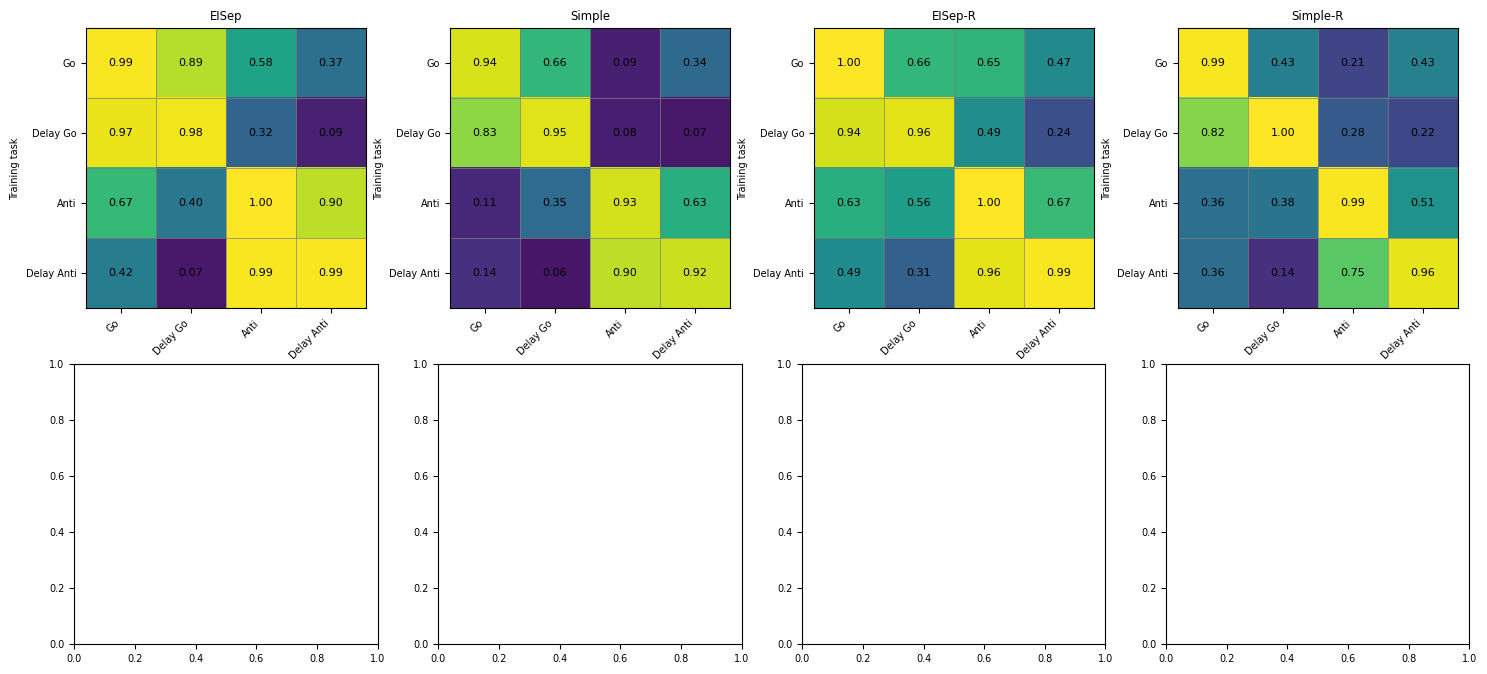

In [ ]:
test_perf_matrix = np.array([x.mean((0,1)) for x in test_perfs])
vmax = test_perf_matrix.max()
vmin = 0
fig, ax = plt.subplots(len(infos)//4+1,4,figsize=(18, 4*(len(infos)//4+1)))
ax = ax.flatten()
task_names = ["Go", "Delay Go",  "Anti", "Delay Anti"]
for i in range(len(infos)):
    ax[i].imshow(test_perf_matrix[i], vmax=vmax, vmin=vmin, cmap='viridis')

    ax[i].set_xticks(range(len(envs)))
    ax[i].set_yticks(range(len(envs)))
    ax[i].set_xticklabels(task_names, rotation=45, ha="right")
    ax[i].set_yticklabels(task_names)

    # grid between cells
    ax[i].set_xticks(np.arange(len(envs)+1)-0.5, minor=True)
    ax[i].set_yticks(np.arange(len(envs)+1)-0.5, minor=True)
    ax[i].grid(which="minor", color="gray", linewidth=0.5)
    ax[i].tick_params(which="minor", bottom=False, left=False)
    ax[i].set_title(legend_names[i])
    ax[i].set_xlabel('Test Task')
    ax[i].set_ylabel('Training task')
    for x in range(len(envs)):
        for y in range(len(envs)):
            ax[i].text(
                y, x,
                f"{test_perf_matrix[i,x,y]:.2f}",
                ha="center", va="center",
                fontsize=8
            )
plt.show()

In [ ]:
model_names = ['eisep', 'simple', 'dann_sgd', 'dann_adam', 'colei_sgd', 'colei_adam', 'dbpn']
legend_names = ['EISep', 'Simple', 'DANN-SGD', 'DANN-Adam', 'ColEI-SGD', 'ColEI-Adam', 'DBPN']
model_colors = ['C1', 'C0', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9']
repeat_times = 10
task_colors = [
    "#3059B9",  # Group 1 - blue (darker) Go
    "#30AB78",  # Group 1 - blue (lighter) Delay Go
    "#C29024",  # Group 2 - orange (darker) Anti
    "#F15E4E",  # Group 2 - orange (lighter) Delay Anti
]
sparsity_ar = np.zeros((len(model_names), n_seed, repeat_times, len(envs)))
for i in range(len(model_names)):
    # print(model_names[i])
    net = init_model(
    ob_size=ob_size + len(envs),
    hidden_size=hidden_size,
    act_size=act_size,
    model_name=model_names[i]
    ).to(device)
    assert infos[i]['net_state_dicts'][0][0][0] is not infos[i]['net_state_dicts'][0][-1][-1], 'shared address'
    for j in range(n_seed):
        for k in range(repeat_times):
            for l in range(len(envs)):
                net.load_state_dict(infos[i]['net_state_dicts'][j][k][l]) # j-th seed, last round, Delay Anti task (last)

                weight = net.get_actual_weight().detach().cpu().numpy()
                sparsity = np.mean(np.abs(weight)<0.1*np.std(np.abs(weight)))
                sparsity_ar[i,j,k,l] = sparsity

fig, ax = plt.subplots(1,1,figsize=(6,3), constrained_layout=True)
fontsize = 15
sparsity_array = sparsity_ar.reshape((len(model_names), n_seed, repeat_times*len(envs)))
mean_sparsity = np.mean(sparsity_array, axis=1)
ste_sparsity = np.std(sparsity_array, axis=1)/np.sqrt(sparsity_array.shape[1])
for i in range(len(model_names)):
    ax.plot(mean_sparsity[i], color=model_colors[i])
    print(model_names[i], mean_sparsity[i][-1])
    ax.errorbar(
        range(len(envs)*repeat_times),
        mean_sparsity[i],
        yerr=ste_sparsity[i],
        fmt='none',
        capsize=1,
        color=model_colors[i]
        )
for j in range(repeat_times):
    for k in range(len(envs)):
        ax.fill_betweenx([0, 1], j*len(envs)+k-0.5, j*len(envs)+k+0.5, color=task_colors[k], alpha=0.1)
ax.set_xmargin(0)
ax.set_xlabel('Trial', fontsize=fontsize-5)
ax.set_ylabel('Sparsity', fontsize=fontsize-5)
ax.tick_params(labelsize=fontsize-5)
ax.set_ylim(0,1)

ax.set_title(f'Continual learning sparsity', fontsize=fontsize+3)
ax.tick_params(labelsize=fontsize)
# plt.tight_layout()
figname = f'./output/continual_learning/CL_sparsity.png'
plt.savefig(figname, dpi=400)
print(figname)
plt.show()
plt.close()


./output/continual_learning_reweight/continual_learning_performance.png


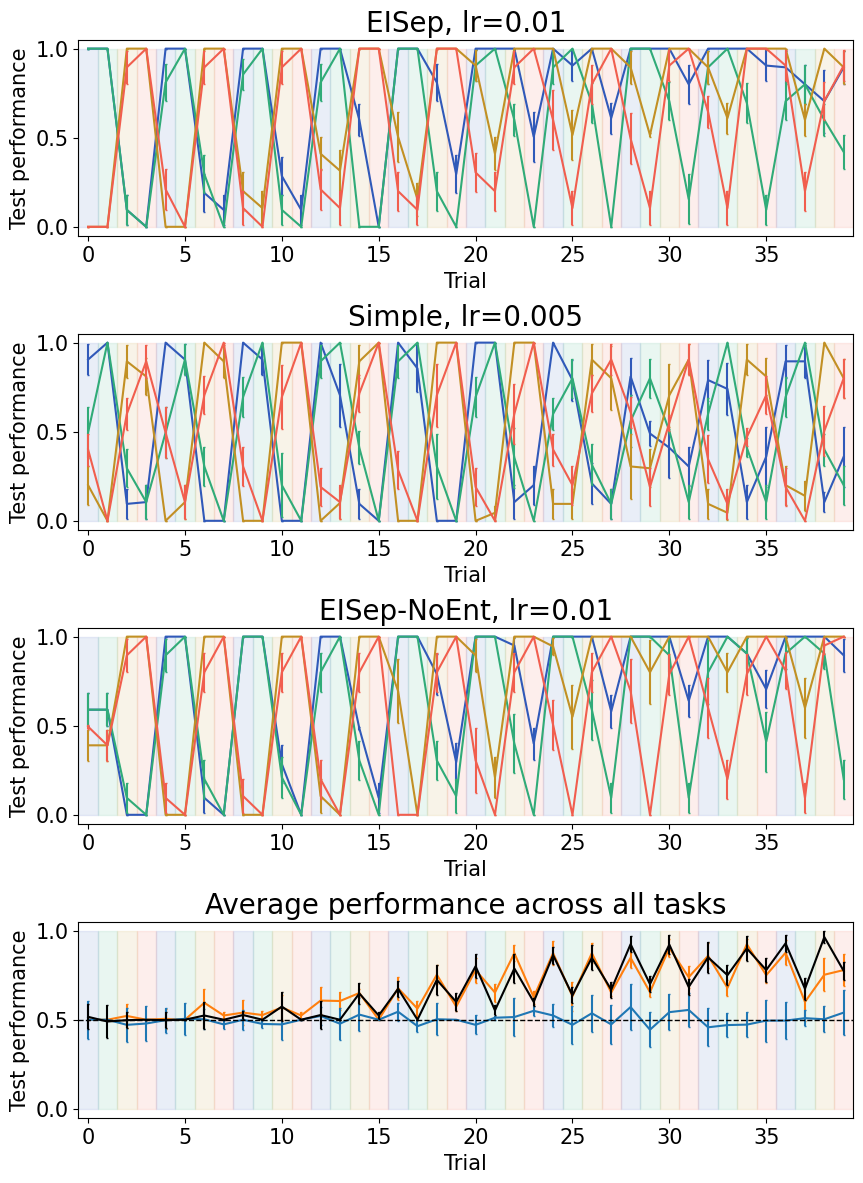

In [ ]:
n_seed = 5
hidden_size = 64
epoch = 200
repeat_times = 10
batch_size = 32
seq_len = 100
fontsize = 20
fig, ax = plt.subplots(len(infos)+1, 1, figsize=(10, 3.5*(len(infos)+1)))
ax = ax.flatten()
# task_colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
task_colors = [
    "#3059B9",  # Group 1 - blue (darker) Go
    "#30AB78",  # Group 1 - blue (lighter) Delay Go
    "#C29024",  # Group 2 - orange (darker) Anti
    "#F15E4E",  # Group 2 - orange (lighter) Delay Anti
]
# titles = ['EISep, lr=1e-2', 'Simple, lr=5e-3', 'Simple, lr=1e-2']
titles = [f'{legend_name}, lr={lr}' for legend_name, lr in zip(legend_names, lrs)]
# summary_labels = ['EISep', 'Simple, lr=5e-3', 'Simple, lr=1e-2']
summary_labels = legend_names

for i in range(len(infos)):
    test_perf = test_perfs[i]
    assert test_perf.shape == (n_seed, repeat_times, len(envs), len(envs))
    test_perf_mean = test_perf.mean(0)
    test_perf_ste = test_perf.std(0)/np.sqrt(n_seed)
    for j in range(len(envs)):
        env_perf_mean = test_perf_mean[...,j].reshape(-1)
        env_perf_ste = test_perf_ste[...,j].reshape(-1)
        ax[i].plot(env_perf_mean, color=task_colors[j])
        ax[i].errorbar(
            range(len(envs)*repeat_times),
            env_perf_mean,
            yerr=env_perf_ste,
            fmt='none',
            capsize=1,
            color=task_colors[j]
            )
    # ax[i].legend()
    ax[i].set_title(titles[i], fontsize=fontsize)
    ax[-1].plot(test_perf_mean.mean(-1).reshape(-1), label=summary_labels[i], color=model_colors[i])
    ax[-1].errorbar(
        range(len(envs)*repeat_times),
        test_perf_mean.mean(-1).reshape(-1),
        yerr=test_perf_ste.mean(-1).reshape(-1),
        fmt='none',
        capsize=1,
        color=model_colors[i]
    )

for a in ax:
    for j in range(repeat_times):
        for k in range(len(envs)):
            a.fill_betweenx([0, 1], j*len(envs)+k-0.5, j*len(envs)+k+0.5, color=task_colors[k], alpha=0.1)
    a.set_xmargin(0)
    a.set_xlabel('Trial', fontsize=fontsize-5)
    a.set_ylabel('Test performance', fontsize=fontsize-5)
    a.tick_params(labelsize=fontsize-5)


ax[-1].set_title('Average performance across all tasks', fontsize=fontsize)
# ax[-1].legend(fontsize=fontsize-5, loc='upper left', framealpha=0.7)

ax[-1].axhline(0.5, color='k', linestyle='--', linewidth=1)

plt.subplots_adjust(hspace=0.5)
# plt.tight_layout()
# figpath = './output/continual_learning_gradient_alignment_reorder/continual_learning_performance.png'
figpath = './output/continual_learning_reweight/continual_learning_performance.png'
os.makedirs(os.path.dirname(figpath), exist_ok=True)
plt.savefig(figpath, dpi=400)
print(figpath)

./output/continual_learning_reweight/final_performance.png


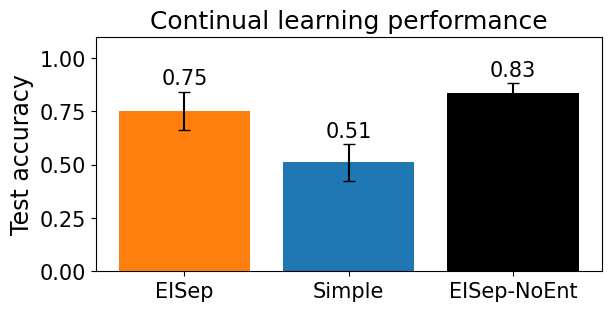

In [ ]:
from net.common import savefig
final_performance_stes = np.zeros((len(infos),2))
for i in range(len(infos)):
    test_perf = test_perfs[i]
    assert test_perf.shape == (n_seed, repeat_times, len(envs), len(envs))
    test_perf_mean = test_perf.mean(0)
    test_perf_ste = test_perf.std(0)/np.sqrt(n_seed)
    final_performance = test_perf_mean[-1].mean()
    final_ste = test_perf_ste[-1].mean()
    final_performance_stes[i,0] = final_performance
    final_performance_stes[i,1] = final_ste

fontsize = 15
fig, ax = plt.subplots(1,1,figsize=(6,3), constrained_layout=True)
for i in range(len(model_names)):
    bars = ax.bar(i, final_performance_stes[i,0], yerr=final_performance_stes[i,1], capsize=4, color=model_colors[i])
    ax.bar_label(bars, fmt='%.2f', padding=2, fontsize=15)

ax.set_ylim(0,1.1)
ax.set_xticks(np.arange(len(model_names)))
# ax.set_xticklabels(legend_names[:len(model_names)], rotation=30, ha='right', fontsize=12)
ax.set_xticklabels(legend_names[:len(model_names)], rotation=0, ha='center', fontsize=12)
ax.set_ylabel('Test accuracy', fontsize=fontsize+2)
ax.set_title('Continual learning performance', fontsize=fontsize+3)
ax.tick_params(labelsize=fontsize)
savefig('./output/continual_learning_reweight/final_performance.png', dpi=400)


In [ ]:
fig, ax = plt.subplots(1,1, figsize=(5,1), constrained_layout=True)
# titles = ['EISep, lr=1e-2', 'Simple, lr=5e-3', 'Simple, lr=1e-2']
# model_colors = ['C1', 'C0', 'C2']
for i in range(len(infos)):
    ax.plot(0, 0, label=titles[i], color=model_colors[i], alpha=1, linewidth=10)
ax.legend(ncol=3, fontsize=fontsize+5, loc='center right', framealpha=1, shadow=False, markerscale=1, frameon=False)
ax.axis('off')
plt.savefig('./output/continual_learning/continual_learning_summary_legend.png', dpi=500,

    bbox_inches='tight',
    pad_inches=0.02)
print('./output/continual_learning/continual_learning_summary_legend.png')

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(5,1), constrained_layout=True)
task_colors = [
    "#3059B9",  # Group 1 - blue (darker)
    "#30AB78",  # Group 1 - blue (lighter)

    "#C29024",  # Group 2 - orange (darker)
    "#F15E4E",  # Group 2 - orange (lighter)
]
task_names = ["Go", "Delay Go", "Anti", "Delay Anti"]
fontsize = 15
for i in range(len(envs)):
        ax.plot(np.zeros((1,)), label=task_names[i], color=task_colors[i], alpha=1, linewidth=10)
ax.legend(ncol=4, fontsize=fontsize, loc='center right', framealpha=1, shadow=False, markerscale=1, frameon=False)
ax.axis('off')
plt.savefig('./output/continual_learning/continual_learning_legend.png', dpi=500,
            
    bbox_inches='tight',
    pad_inches=0.02)
print('./output/continual_learning/continual_learning_legend.png')
# plt.show()

In [ ]:
import os
model_names = ['simple', ]
# model_names = ['dbpn', 'colei_sgd', 'colei_adam', 'dann_sgd', 'dann_adam', 'absolute_eisep']

lrs = [1e-2]
# lrs = [5e-3]
# model_names = ['eisep']
for i, model_name in enumerate(model_names):
    print(model_name)
    info = multiple_train(model_name, lrs[i])
    path = f'./result/continual_learning_reweight/lr{lrs[i]}_{model_name}_info.pkl'
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, 'wb') as f:
        pkl.dump(info, f)
raise ValueError('stop here')

In [ ]:
import pickle as pkl
import numpy as np
import os

paths = ['./result/continual_learning_reweight/temp_None/lr0.01_eisep_info.pkl', 
    './result/continual_learning_reweight/hidden_64/lr0.01_eisep_info.pkl', 
            './result/continual_learning_reweight/hidden_64/lr0.005_simple_info.pkl',
        './result/continual_learning_reweight/hidden_64/lr0.01_simple_info.pkl']
infos = [pkl.load(open(path, 'rb')) for path in paths]
test_perfs = [info['test_perf_all'] for info in infos]
n_seed = 5
hidden_size = 64
epoch = 200
repeat_times = 10
batch_size = 32
seq_len = 100
fontsize = 20
fig, ax = plt.subplots(len(infos)+1, 1, figsize=(10, 3*(len(infos)+1)))
ax = ax.flatten()
task_colors = [
    "#3059B9",  # Group 1 - blue (darker)
    "#30AB78",  # Group 1 - blue (lighter)

    "#C29024",  # Group 2 - orange (darker)
    "#F15E4E",  # Group 2 - orange (lighter)
]
titles = ['EISep, lr=0.005', 'EISep, lr=0.01', 'Simple, lr=0.005', 'Simple, lr=0.01']
summary_labels = ['EISep, lr=0.005', 'EISep, lr=0.01', 'Simple, lr=0.005', 'Simple, lr=0.01']
model_colors = ['C3', 'C1', 'C0', 'C2']
for i in range(len(infos)):
    test_perf = test_perfs[i]
    assert test_perf.shape == (n_seed, repeat_times, len(envs), len(envs))
    test_perf_mean = test_perf.mean(0)
    test_perf_ste = test_perf.std(0)/np.sqrt(n_seed)
    for j in range(len(envs)):
        env_perf_mean = test_perf_mean[...,j].reshape(-1)
        env_perf_ste = test_perf_ste[...,j].reshape(-1)
        ax[i].plot(env_perf_mean, color=task_colors[j], label=f'{task_ids[i]} acc')
        ax[i].errorbar(
            range(len(envs)*repeat_times),
            env_perf_mean,
            yerr=env_perf_ste,
            fmt='none',
            capsize=1,
            color=task_colors[j]
            )
    # ax[i].legend()
    ax[i].set_title(titles[i], fontsize=fontsize)
    ax[-1].plot(test_perf_mean.mean(-1).reshape(-1), label=summary_labels[i], color=model_colors[i])
    ax[-1].errorbar(
        range(len(envs)*repeat_times),
        test_perf_mean.mean(-1).reshape(-1),
        yerr=test_perf_ste.mean(-1).reshape(-1),
        fmt='none',
        capsize=1,
        color=model_colors[i]
    )

for a in ax:
    for j in range(repeat_times):
        for k in range(len(envs)):
            a.fill_betweenx([0, 1], j*len(envs)+k-0.5, j*len(envs)+k+0.5, color=task_colors[k], alpha=0.1)
    a.set_xmargin(0)
    a.set_xlabel('Trial', fontsize=fontsize-5)
    a.set_ylabel('Test performance', fontsize=fontsize-5)
    a.tick_params(labelsize=fontsize-5)


ax[-1].set_title('Average performance across all tasks', fontsize=fontsize)
# ax[-1].legend(fontsize=fontsize-5, loc='upper left', framealpha=0.7)

ax[-1].axhline(0.5, color='k', linestyle='--', linewidth=1)

plt.subplots_adjust(hspace=0.7)
# plt.tight_layout()
figpath = './output/continual_learning/continual_learning_performance.png'
os.makedirs(os.path.dirname(figpath), exist_ok=True)
plt.savefig(figpath, dpi=400)
print(figpath)

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(5,1), constrained_layout=True)
# titles = ['EISep, lr=1e-2', 'Simple, lr=5e-3', 'Simple, lr=1e-2']
# model_colors = ['C1', 'C0', 'C2']
for i in range(len(infos)):
    ax.plot(0, 0, label=titles[i], color=model_colors[i], alpha=1, linewidth=10)
ax.legend(ncol=2, fontsize=fontsize, loc='center right', framealpha=1, shadow=False, markerscale=1, frameon=False)
ax.axis('off')
plt.savefig('./output/continual_learning/continual_learning_summary_legend.png', dpi=500,
            
    bbox_inches='tight',
    pad_inches=0.02)
print('./output/continual_learning/continual_learning_summary_legend.png')

In [ ]:
from net.common import savefig
final_performance_stes = np.zeros((len(infos),2))
for i in range(len(infos)):
    test_perf = test_perfs[i]
    assert test_perf.shape == (n_seed, repeat_times, len(envs), len(envs))
    test_perf_mean = test_perf.mean(0)
    test_perf_ste = test_perf.std(0)/np.sqrt(n_seed)
    final_performance = test_perf_mean[-1].mean()
    final_ste = test_perf_ste[-1].mean()
    final_performance_stes[i,0] = final_performance
    final_performance_stes[i,1] = final_ste

fontsize = 15
fig, ax = plt.subplots(1,1,figsize=(6,3), constrained_layout=True)
for i in range(len(infos)):
    bars = ax.bar(i, final_performance_stes[i,0], yerr=final_performance_stes[i,1], capsize=4, color=model_colors[i])
    ax.bar_label(bars, fmt='%.2f', padding=2, fontsize=15)

ax.set_ylim(0,1.1)
ax.set_xticks(np.arange(len(summary_labels)))
ax.set_xticklabels(summary_labels, rotation=30, ha='right', fontsize=12)
ax.set_ylabel('Test accuracy', fontsize=fontsize+2)
ax.set_title('Performance at the final round', fontsize=fontsize+3)
ax.tick_params(labelsize=fontsize)
savefig('./output/continual_learning_reweight/final_performance.png', dpi=400)

In [ ]:
# from docs.examples.net import eisep

eisep_info = infos[0]
simple_info = infos[1]
n_seed = test_perfs[0].shape[0]
n_repeat_times = test_perfs[0].shape[1]
loss_idx = 2
# n_seed = test_perf_EI_all.shape[0]

# loss: [n_seed, n_repeat_times, n_train_envs, n_epoch, 3]
loss_log_ei = eisep_info['loss_log_all'][...,loss_idx]
loss_log_simple = simple_info['loss_log_all'][...,loss_idx]
# print(loss_log_ei.shape, loss_log_simple.shape)
# gradient_log_ei = eisep_info['gradient_log_all'][...,0]
# gradient_log_simple = simple_info['gradient_log_all'][...,0]
n_repeat_times = loss_log_ei.shape[1]
n_env = loss_log_ei.shape[2]
n_epoch = loss_log_ei.shape[3]
# loss_log_ei = loss_log_ei_origin.reshape(n_seed, -1)
# loss_log_simple = loss_log_simple_origin.reshape(n_seed, -1)

def plot_multiphase_log(log, n_env, n_epoch, n_repeat_times, ax, ylabel, title):
    assert log.shape == (n_seed, n_repeat_times, n_env, n_epoch)
    # log = log.reshape(n_seed*n_repeat_times, n_env, n_epoch)
    fontsize = 15
    log = np.where(np.isnan(log),0,log)
    mean_log = np.mean(log, axis=0)
    std_log = np.std(log, axis=0)/np.sqrt(log.shape[0])
    for i in range(n_repeat_times):
        for j in range(n_env):
            idx = i*n_env+j
            ax.plot(np.arange(idx*n_epoch, (idx+1)*n_epoch), mean_log[i,j], label=f'Env {i+1}', color=task_colors[j])
            ax.fill_between(np.arange(idx*n_epoch, (idx+1)*n_epoch), mean_log[i,j]-std_log[i,j], mean_log[i,j]+std_log[i,j], color=task_colors[j], alpha=0.3)
            ax.fill_betweenx([1e-10, 1e32], idx*n_epoch, (idx+1)*n_epoch, color=task_colors[j], alpha=0.1)
    # for j in range(n_env):
        # ax.plot(np.arange(j*n_epoch, (j+1)*n_epoch), mean_log[j], label=f'Env {i+1}', color=task_colors[j])
        # ax.fill_between(np.arange(j*n_epoch, (j+1)*n_epoch), mean_log[j]-std_log[j], mean_log[j]+std_log[j], color=task_colors[j], alpha=0.3)
        # ax.fill_betweenx([mean_log.min()/1e3, mean_log.max()], j*n_epoch, (j+1)*n_epoch, color=task_colors[j], alpha=0.1)
    ax.set_xlabel('Epoch', fontsize=fontsize)
    ax.set_ylabel(ylabel, fontsize=fontsize)
    ax.set_title(title, fontsize=fontsize)
    ax.set_xlim(0,n_repeat_times*n_env*n_epoch)
    ax.tick_params(labelsize=fontsize-3)
    # ax.set_xlim(0,n_env*n_epoch)
    # ax.legend()
    ax.set_yscale('log')
    ax.set_ylim([1e-8, 1e1])
    return

# fig, ax = plt.subplots(8, 2, figsize=(10, 18))
fig, ax = plt.subplots(4,1, figsize=(6, 9))
ax = ax.flatten()
# print(loss_log_simple)
# titles = ['EISep', 'Simple, lr=5e-3', 'Simple, lr=1e-2']
titles = ['EISep no entropy', 'EISep normal', 'Simple 0', 'Simple 1']
for i, info in enumerate(infos):
    loss_log = info['loss_log_all'][...,loss_idx]
    plot_multiphase_log(loss_log, n_env, n_epoch, n_repeat_times, ax[i], 'Entropy loss', titles[i])
# plot_multiphase_log(loss_log_ei, n_env, n_epoch, n_repeat_times, ax[0], 'Decoding loss', 'EISep')
# plot_multiphase_log(loss_log_simple, n_env, n_epoch, n_repeat_times, ax[1], 'Decoding loss', 'Simple')
# titles = ['Input weight', 'Input bias', 'Recurrent weight', 'Recurrent bias', 'Output weight', 'Output bias', 'E/I mask']
# for i in range(7):
#     plot_multiphase_log(eisep_info['gradient_log_all'][...,i], n_env, n_epoch, n_repeat_times, ax[2+i*2], 'Gradient norm', titles[i])
#     plot_multiphase_log(simple_info['gradient_log_all'][...,i], n_env, n_epoch, n_repeat_times, ax[3+i*2], 'Gradient norm', titles[i])

plt.tight_layout()
plt.subplots_adjust(hspace=0.7)
# plt.show()

figpath = './output/continual_learning/continual_learning_loss.png'
savefig(figpath)

In [ ]:
simple_weight = simple_net.lstm.Wrec_free.detach().cpu().numpy()
fig, ax = plt.subplots(1, 1, figsize=(6, 3))
im = ax.imshow(simple_weight, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_title('Simple RNN weight')
plt.colorbar(im, ax=ax)

In [ ]:
model_names = ['eisep', 'simple']
legend_names = ['EISep', 'Simple']
model_colors = ['C1', 'C0', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9']
n_seed = 5
hidden_size = 64
epoch = 200
repeat_times = 10
# model_names = ['eisep', 'simple', 'absolute_eisep', 'fixed_eisep', 'entryei', 'eisep_init_ColEI', 'eisep_init_DBPN']
# legend_names = ['EISep', 'Simple', 'Abs-EISep', 'Fixed-EISep', 'EntryEI', 'EISep(N1)', 'EISep(N2)']
# model_colors = ['C1', 'C0', 'C7', 'C8', 'C9', '#E69F00', '#009E73']

lrs = [best_lr_dict[model_name] for model_name in model_names]
paths = [f'./result/continual_learning_gradient_alignment/lr{lr}_{model_name}_info.pkl' for model_name, lr in zip(model_names, lrs)]
for i in range(len(paths)):
    print(paths[i])
infos = [pkl.load(open(path, 'rb')) for path in paths]
delta_W_logs = [info['delta_W_log_all'] for info in infos]
print(delta_W_logs[0].shape)
corr_average_all = np.zeros((len(delta_W_logs), len(envs), len(envs)))

fig, ax = plt.subplots(1, 2, figsize=(7,3), constrained_layout=True)

for i in range(len(delta_W_logs)):
    delta_W_log = delta_W_logs[i].reshape(n_seed * repeat_times, len(envs), hidden_size**2)
    corr_matrix = np.zeros((n_seed * repeat_times, len(envs), len(envs)))

    for j in range(n_seed * repeat_times):
        corr_matrix[j] = np.corrcoef(delta_W_log[j])
        # np.cov()
        # corr_matrix[j] = delta_W_log[j]@delta_W_log[j].T

    corr_average_all[i] = np.nanmean(corr_matrix, 0) - np.eye(len(envs))

# symmetric range around zero (better for correlation matrices)
vmax = np.abs(corr_average_all).max()
vmin = -vmax

im = None
task_names = ["Go", "Delay Go", "Anti", "Delay Anti"]
for i in range(len(delta_W_logs)):
    im = ax[i].imshow(
        corr_average_all[i],
        vmin=vmin,
        vmax=vmax,
        cmap="RdBu_r",
        aspect="equal"
    )

    # ticks
    ax[i].set_xticks(range(len(envs)))
    ax[i].set_yticks(range(len(envs)))
    ax[i].set_xticklabels(task_names, rotation=45, ha="right")
    ax[i].set_yticklabels(task_names)

    # grid between cells
    ax[i].set_xticks(np.arange(len(envs)+1)-0.5, minor=True)
    ax[i].set_yticks(np.arange(len(envs)+1)-0.5, minor=True)
    ax[i].grid(which="minor", color="gray", linewidth=0.5)
    ax[i].tick_params(which="minor", bottom=False, left=False)
    ax[i].set_title(legend_names[i])

    for x in range(len(envs)):
        for y in range(len(envs)):
            ax[i].text(
                y, x,
                f"{corr_average_all[i,x,y]:.2f}",
                ha="center", va="center",
                fontsize=8
            )

# shared colorbar
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
# cbar.set_label("Weight change correlation")
fig.suptitle("Weight change correlation", fontsize=15)

# plt.tight_layout()
plt.savefig('./output/continual_learning/CL_weight_change_correlation.png', dpi=400)
print('./output/continual_learning/CL_weight_change_correlation.png')
plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pickle as pkl

# ============================================================
# settings
# ============================================================
model_names = ['eisep', 'simple']
legend_names = ['EISep', 'Simple']
model_colors = ['C1', 'C0']
task_names = ["Go", "Delay Go", "Anti", "Delay Anti"]

n_seed = 5
repeat_times = 10
hidden_size = 64
n_tasks = 4

# choose ONE of the following mask definitions:
TOPK_FRAC = 0.10          # top 10% largest |ΔW| entries per task
ENERGY_FRAC = None        # e.g. 0.80 means smallest set explaining 80% update energy
USE_SIGNED_OVERLAP = True # whether to also compute sign agreement on overlapping weights

# ============================================================
# load
# ============================================================
lrs = [best_lr_dict[model_name] for model_name in model_names]
paths = [
    f'./result/continual_learning_gradient_alignment/lr{lr}_{model_name}_info.pkl'
    for model_name, lr in zip(model_names, lrs)
]

for p in paths:
    print(p)

infos = [pkl.load(open(path, 'rb')) for path in paths]
delta_W_logs = [info['delta_W_log_all'] for info in infos]

# expected shape: (n_seed, repeat_times, n_tasks, H, H)
print("delta_W_log_all shape:", delta_W_logs[0].shape)


# ============================================================
# helpers
# ============================================================
def build_topk_mask(vec, topk_frac=0.1):
    """
    vec: 1D array of shape (P,)
    returns binary mask of same shape selecting top-k by |value|
    """
    abs_vec = np.abs(vec)
    k = max(1, int(np.ceil(topk_frac * abs_vec.size)))
    idx = np.argpartition(abs_vec, -k)[-k:]
    mask = np.zeros_like(abs_vec, dtype=bool)
    mask[idx] = True
    return mask


def build_energy_mask(vec, energy_frac=0.8):
    """
    Select the smallest set of weights whose squared magnitude explains
    energy_frac of total squared update energy.
    """
    abs_sq = np.abs(vec) ** 2
    order = np.argsort(abs_sq)[::-1]
    sorted_energy = abs_sq[order]
    csum = np.cumsum(sorted_energy)
    total = csum[-1]

    if total <= 0:
        mask = np.zeros_like(vec, dtype=bool)
        return mask

    cutoff = energy_frac * total
    k = np.searchsorted(csum, cutoff) + 1
    idx = order[:k]

    mask = np.zeros_like(vec, dtype=bool)
    mask[idx] = True
    return mask


def jaccard(mask1, mask2):
    inter = np.logical_and(mask1, mask2).sum()
    union = np.logical_or(mask1, mask2).sum()
    if union == 0:
        return np.nan
    return inter / union


def overlap_ratio(mask1, mask2):
    """
    Intersection relative to mask1 size and mask2 size.
    Useful because Jaccard can look small when masks are sparse.
    """
    inter = np.logical_and(mask1, mask2).sum()
    s1 = mask1.sum()
    s2 = mask2.sum()
    out1 = np.nan if s1 == 0 else inter / s1
    out2 = np.nan if s2 == 0 else inter / s2
    return out1, out2


def signed_agreement(vec1, vec2, mask1, mask2):
    """
    On overlapping selected weights, measure whether the signs agree.
    Returns:
      agreement = fraction of overlapping weights with same sign
      mean_sign_product = mean(sign(v1)*sign(v2)) on overlap, in [-1,1]
    """
    overlap = np.logical_and(mask1, mask2)
    if overlap.sum() == 0:
        return np.nan, np.nan

    s1 = np.sign(vec1[overlap])
    s2 = np.sign(vec2[overlap])

    # treat exact zeros conservatively
    valid = (s1 != 0) & (s2 != 0)
    if valid.sum() == 0:
        return np.nan, np.nan

    s1 = s1[valid]
    s2 = s2[valid]
    same = (s1 == s2).mean()
    mean_prod = np.mean(s1 * s2)
    return same, mean_prod


def make_mask(vec):
    if TOPK_FRAC is not None:
        return build_topk_mask(vec, topk_frac=TOPK_FRAC)
    elif ENERGY_FRAC is not None:
        return build_energy_mask(vec, energy_frac=ENERGY_FRAC)
    else:
        raise ValueError("Set either TOPK_FRAC or ENERGY_FRAC.")


# ============================================================
# compute overlap matrices
# ============================================================
jaccard_mean_all = np.zeros((len(model_names), n_tasks, n_tasks))
jaccard_sem_all  = np.zeros((len(model_names), n_tasks, n_tasks))

same_sign_mean_all = np.zeros((len(model_names), n_tasks, n_tasks))
same_sign_sem_all  = np.zeros((len(model_names), n_tasks, n_tasks))

# optional raw values for statistics / boxplots
all_pairwise_jaccards = [[] for _ in range(len(model_names))]

for m in range(len(model_names)):
    # shape: (n_seed, repeat_times, n_tasks, H, H)
    dw = delta_W_logs[m]

    # flatten first two dims into samples
    Y = dw.reshape(n_seed * repeat_times, n_tasks, hidden_size * hidden_size)

    # store sample-level matrices
    jaccard_mats = np.full((Y.shape[0], n_tasks, n_tasks), np.nan)
    same_sign_mats = np.full((Y.shape[0], n_tasks, n_tasks), np.nan)

    for s in range(Y.shape[0]):
        task_vecs = Y[s]  # shape: (4, P)
        masks = [make_mask(task_vecs[t]) for t in range(n_tasks)]

        for i in range(n_tasks):
            for j in range(n_tasks):
                jaccard_mats[s, i, j] = jaccard(masks[i], masks[j])

                if USE_SIGNED_OVERLAP:
                    same, mean_prod = signed_agreement(
                        task_vecs[i], task_vecs[j],
                        masks[i], masks[j]
                    )
                    same_sign_mats[s, i, j] = same

        # collect off-diagonal entries for summary stats
        tri_i, tri_j = np.triu_indices(n_tasks, k=1)
        all_pairwise_jaccards[m].extend(jaccard_mats[s, tri_i, tri_j].tolist())

    jaccard_mean_all[m] = np.nanmean(jaccard_mats, axis=0)
    jaccard_sem_all[m]  = np.nanstd(jaccard_mats, axis=0) / np.sqrt(Y.shape[0])

    if USE_SIGNED_OVERLAP:
        same_sign_mean_all[m] = np.nanmean(same_sign_mats, axis=0)
        same_sign_sem_all[m]  = np.nanstd(same_sign_mats, axis=0) / np.sqrt(Y.shape[0])


# ============================================================
# plot heatmaps: Jaccard overlap
# ============================================================
fig, ax = plt.subplots(1, len(model_names), figsize=(7, 3), constrained_layout=True)

if len(model_names) == 1:
    ax = [ax]

vmax = np.nanmax(jaccard_mean_all)
vmin = 0.0
im = None

for m in range(len(model_names)):
    im = ax[m].imshow(
        jaccard_mean_all[m],
        vmin=vmin,
        vmax=vmax,
        cmap="viridis",
        aspect="equal"
    )

    ax[m].set_title(legend_names[m])
    ax[m].set_xticks(range(n_tasks))
    ax[m].set_yticks(range(n_tasks))
    ax[m].set_xticklabels(task_names, rotation=45, ha="right")
    ax[m].set_yticklabels(task_names)

    ax[m].set_xticks(np.arange(n_tasks + 1) - 0.5, minor=True)
    ax[m].set_yticks(np.arange(n_tasks + 1) - 0.5, minor=True)
    ax[m].grid(which="minor", color="gray", linewidth=0.5)
    ax[m].tick_params(which="minor", bottom=False, left=False)

    for i in range(n_tasks):
        for j in range(n_tasks):
            ax[m].text(
                j, i,
                f"{jaccard_mean_all[m, i, j]:.2f}",
                ha="center", va="center",
                fontsize=8,
                color="white" if jaccard_mean_all[m, i, j] < 0.5 * vmax else "black"
            )

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
label = f"Top-{int(TOPK_FRAC * 100)}% weight-mask Jaccard overlap" if TOPK_FRAC is not None \
        else f"Energy-{int(ENERGY_FRAC * 100)}% weight-mask Jaccard overlap"
# cbar.set_label(label)
fig.suptitle(label, fontsize=15)
savefig('./output/continual_learning/CL_weight_change_mask_overlap.png', dpi=400)
plt.show()

# ============================================================
# optional plot: sign agreement on overlapping weights
# ============================================================
if USE_SIGNED_OVERLAP:
    fig, ax = plt.subplots(1, len(model_names), figsize=(7, 3), constrained_layout=True)

    if len(model_names) == 1:
        ax = [ax]

    vmax = 1.0
    vmin = 0.0
    im = None

    for m in range(len(model_names)):
        im = ax[m].imshow(
            same_sign_mean_all[m],
            vmin=vmin,
            vmax=vmax,
            cmap="magma",
            aspect="equal"
        )

        ax[m].set_title(legend_names[m])
        ax[m].set_xticks(range(n_tasks))
        ax[m].set_yticks(range(n_tasks))
        ax[m].set_xticklabels(task_names, rotation=45, ha="right")
        ax[m].set_yticklabels(task_names)

        ax[m].set_xticks(np.arange(n_tasks + 1) - 0.5, minor=True)
        ax[m].set_yticks(np.arange(n_tasks + 1) - 0.5, minor=True)
        ax[m].grid(which="minor", color="gray", linewidth=0.5)
        ax[m].tick_params(which="minor", bottom=False, left=False)

        for i in range(n_tasks):
            for j in range(n_tasks):
                val = same_sign_mean_all[m, i, j]
                txt = "nan" if np.isnan(val) else f"{val:.2f}"
                ax[m].text(
                    j, i, txt,
                    ha="center", va="center",
                    fontsize=8,
                    color="white" if (not np.isnan(val) and val < 0.6) else "black"
                )

    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Same-sign fraction on overlapping selected weights")
    plt.show()


# ============================================================
# summary plot: off-diagonal pairwise overlaps
# ============================================================
fig, ax = plt.subplots(1, 1, figsize=(4, 3.2))

box_data = [np.array(x)[np.isfinite(x)] for x in all_pairwise_jaccards]
ax.boxplot(box_data, tick_labels=legend_names, widths=0.6)
ax.set_ylabel("Pairwise Jaccard overlap")
ax.set_title("Task-pair weight overlap", fontsize=15)

# overlay means
for m in range(len(model_names)):
    y = np.nanmean(box_data[m])
    ax.scatter(m + 1, y, s=35, zorder=3)

plt.tight_layout()
savefig('./output/continual_learning/task_pair_weight_overlap_boxplot.png', dpi=400)
plt.show()


# ============================================================
# print summaries
# ============================================================
tri_i, tri_j = np.triu_indices(n_tasks, k=1)
for m in range(len(model_names)):
    offdiag = jaccard_mean_all[m, tri_i, tri_j]
    print(f"\n{legend_names[m]}")
    print("Mean off-diagonal Jaccard overlap:", np.nanmean(offdiag))
    print("Pairwise overlaps:")
    for i, j in zip(tri_i, tri_j):
        print(f"  {task_names[i]} vs {task_names[j]}: "
              f"{jaccard_mean_all[m, i, j]:.4f} ± {jaccard_sem_all[m, i, j]:.4f}")

In [ ]:
# net = SimpleNet(num_h=64, ob_size=ob_size, act_size=act_size).to(device)
# net = train(env1, net)
# print(test(env1, net))

In [ ]:
# net = Net(num_h=64, ob_size=ob_size, act_size=act_size, entropy_loss=True).to(device)
# test_perf_EI = continual_learning([env1, env2], net)
# net = SimpleNet(num_h=64, ob_size=ob_size, act_size=act_size).to(device)
# test_perf_simple = continual_learning([env1, env2], net)

In [ ]:
# def train(env, net):
#     seq_len = 100
#     batch_size = 32

#     criterion = nn.CrossEntropyLoss()
#     optimizer = torch.optim.Adam(net.parameters(), lr=1e-2)
#     dataset = ngym.Dataset(env, batch_size=batch_size, seq_len=seq_len)

#     running_loss = 0.0
#     running_entropy = 0.0
#     running_decoding_loss = 0.0
#     for i in range(EPOCHS):
#         # net.set_temperature(get_temperature(i))
#         # if i % 10 == 9:
#             # print('Epoch:', i+1, 'Temperature:', net.temperature)
#         inputs, labels = dataset()
#         inputs = torch.from_numpy(inputs).type(torch.float).to(device)
#         labels = torch.from_numpy(labels.flatten()).type(torch.long).to(device)

#         # zero the parameter gradients
#         optimizer.zero_grad()

#         # forward + backward + optimize
#         outputs, eimask_logit, hidden = net(inputs)

#         # eimask_prob = F.softmax(eimask_logit, dim=-1)
#         # eimask_entropy = -torch.sum(eimask_prob * torch.log(eimask_prob + 1e-10), dim=-1)

#         decoding_loss = criterion(outputs.view(-1, act_size), labels)
#         # entropy_loss = torch.mean(eimask_entropy)  # Add entropy regularization

#         # loss = decoding_loss
#         loss = decoding_loss

#         loss.backward()
#         optimizer.step()

#         # print statistics
#         running_loss += loss.item()
#         # running_entropy += entropy_loss.item()
#         running_decoding_loss += decoding_loss.item()
#         if (i+1) % 100 == 0:
#             print('{:d} loss: {:0.5f}'.format(i+1, running_loss / 100))
#             print('Entropy loss: {:0.5f}, Decoding loss: {:0.5f}'.format(
#                 running_entropy / 100, running_decoding_loss / 100))
#             running_loss = 0.0

#     print('Finished Training')
#     return net

In [ ]:
# EI_env2_performance = [0.995, 1.0]
# simple_env2_performance = [1.0, 0.545]
# fig, ax = plt.subplots(figsize=(4,3))
# ax.plot(EI_env2_performance, label='EI', marker='o')
# ax.plot(simple_env2_performance, label='Simple', marker='o')
# ax.set_xticks([0, 1])
# ax.set_xticklabels(['Delay-Go', 'MultiDM'])
# ax.set_ylabel('Test performance on Delay-Go')
# ax.set_xlabel('Training task')
# plt.legend()
# plt.tight_layout()
# plt.show()
